# Benchmarking Python Differential Expression Tools Across Replicate Numbers
**BIOL 5340 final project:**

**Allan Thiyagaseelan (1002304701)**

**Habib Wouleo Fipa (100233966)**

**Question:** As the number of biological replicates per condition drops from 40+ to 3, what fraction of the full-data
reference differentially expressed (DE) genes do four Python DE methods still find, and how well do they agree?

**Methods compared:** PyDESeq2 · edgeR (InMoose port) · limma (InMoose port) · Wilcoxon rank-sum test

**Data:** Yeast (*S. cerevisiae*) wild type vs. Δsnf2 mutant, 48 replicates each (Schurch et al., 2016, *RNA*;
ENA PRJEB5348). Counts come from https://github.com/bartongroup/profDGE48.

1. **Validation pilot:** TMM normalization and the full-data results are checked against trusted implementations.
   The benchmark does not start unless every check passes.
2. **Benchmark:** `QUICK_MODE = True` takes about 10–15 min on Colab (5 draws per sample size); set it to `False`
   for the final results (20 draws, about 1–1.5 h).
3. **Evaluation:** figures and tables.

Every result is cached (`results/` and `cache/`), so if Colab disconnects, Run all again and it continues where it stopped.

In [ ]:
# 1. Install packages (about 1 minute)
!pip install -q pydeseq2==0.5.4 inmoose==0.9.1 conorm==1.2.0 upsetplot

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [ ]:
# 2. Settings and imports
QUICK_MODE = True                      # True = 5 draws per n (fast test); False = 20 draws (final results)
N_DRAWS = 5 if QUICK_MODE else 20
SAMPLE_SIZES = [3, 4, 6, 8, 12, 20]    # replicates per condition in each subsample
FDR = 0.05                             # adjusted p-value cutoff used for every method
SEED = 2026
OUT = "results"                        # all tables and figures are saved here

import os, sys, glob, tarfile, time, urllib.request, warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu, rankdata, spearmanr
warnings.filterwarnings("ignore"); logging.getLogger().setLevel(logging.ERROR)
os.makedirs(OUT, exist_ok=True)
METHODS = ["PyDESeq2", "edgeR", "limma", "Wilcoxon"]
COLORS = dict(zip(METHODS, ["#2E86AB", "#E07A5F", "#3D9970", "#8E6C8A"]))
print("Draws per sample size:", N_DRAWS)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Draws per sample size: 5


In [ ]:
# 3. Download the count data and the published R results (about 3 MB)
BASE = "https://raw.githubusercontent.com/bartongroup/profDGE48/master/"
FILES = ["Preprocessed_data/WT_countdata.tar.gz", "Preprocessed_data/Snf2_countdata.tar.gz",
         "Bad_replicate_identification/exclude.lst"] + \
        [f"Preprocessed_data/full_rep_gold_standards/R3.2.2/{t}_package_default.txt" for t in ["deseq2", "edgeR", "limma"]]
os.makedirs("data/counts", exist_ok=True)
for f in FILES:
    local = os.path.join("data", os.path.basename(f))
    if not os.path.exists(local):
        urllib.request.urlretrieve(BASE + f, local)
    if local.endswith(".tar.gz"):
        with tarfile.open(local) as t:
            try:
                t.extractall("data/counts", filter="data")
            except TypeError:                                 # older Python without the filter argument
                t.extractall("data/counts")
print(len(glob.glob("data/counts/*.gbgout")), "count files downloaded")

96 count files downloaded


6887 genes x 86 samples  (42 WT, 44 Snf2)


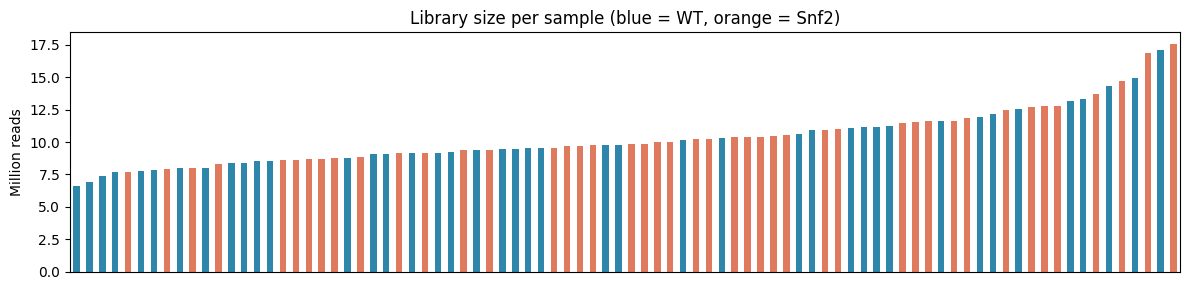

In [ ]:
# 4. Build the count matrix (genes x samples) and remove the 10 bad replicates flagged by the authors
bad = {l.strip() for l in open("data/exclude.lst") if l.strip()}
cols = {}
for f in sorted(glob.glob("data/counts/*.gbgout")):
    name = os.path.basename(f).replace(".gbgout", "")
    if name in bad:
        continue
    cols[name.split("_allLanes")[0]] = pd.read_csv(f, sep="\t", header=None, index_col=0)[1]
counts = pd.DataFrame(cols)
counts = counts[counts.sum(axis=1) > 0]                       # drop genes with no reads at all
groups = pd.Series(["WT" if c.startswith("WT") else "Snf2" for c in counts.columns], index=counts.columns)
WT, SNF2 = list(groups[groups == "WT"].index), list(groups[groups == "Snf2"].index)
print(f"{counts.shape[0]} genes x {counts.shape[1]} samples  ({len(WT)} WT, {len(SNF2)} Snf2)")
counts.to_csv(f"{OUT}/count_matrix_clean.csv")

# Quick look: library sizes per sample
ax = (counts.sum() / 1e6).sort_values().plot.bar(figsize=(12, 3), color=[COLORS["PyDESeq2"] if groups[c] == "WT" else COLORS["edgeR"] for c in (counts.sum()).sort_values().index])
ax.set_ylabel("Million reads"); ax.set_xticks([]); ax.set_title("Library size per sample (blue = WT, orange = Snf2)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig0_library_sizes.png", dpi=150); plt.show()

## The four DE methods
Each function takes a count table (genes × samples) for one WT group and one Snf2 group and returns, for every
gene, a **log2 fold change** (Snf2 vs. WT) and a **BH-adjusted p-value (padj)**. A gene counts as "DE" if padj < 0.05.

* **PyDESeq2**: Python re-implementation of DESeq2 (negative binomial model, Wald test).
* **edgeR (InMoose)**: TMM normalization + exact test, the same settings the original R study used.
  InMoose has no `calcNormFactors`, so TMM is implemented below following the edgeR algorithm.
* **limma (InMoose)**: InMoose has no `voom`, so this uses the *limma-trend* variant (log-CPM + eBayes with
  `trend=True`). This is a documented difference from the R study, which used voom.
* **Wilcoxon**: rank-sum test on TMM-normalized CPM per gene (recommended for large samples by Li et al., 2022).

In [ ]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from inmoose import edgepy, limma as ilimma

def bh(p):
    """Benjamini-Hochberg adjusted p-values (NaN-safe)."""
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    pv = p[ok]; n = len(pv); order = np.argsort(pv)
    adj = np.minimum.accumulate((pv[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    res = np.empty(n); res[order] = np.minimum(adj, 1); out[ok] = res
    return out

def tmm_factors(c, trim_m=0.3, trim_a=0.05):
    """TMM normalization factors (Robinson & Oshlack 2010), as in edgeR::calcNormFactors."""
    c = np.asarray(c, float); lib = c.sum(0)
    uq = np.quantile(c / lib, 0.75, axis=0)
    ref = int(np.argmin(np.abs(uq - uq.mean())))
    f = np.ones(c.shape[1])
    for j in range(c.shape[1]):
        o, r, no, nr = c[:, j], c[:, ref], lib[j], lib[ref]
        with np.errstate(divide="ignore", invalid="ignore"):
            logR = np.log2((o / no) / (r / nr)); absE = (np.log2(o / no) + np.log2(r / nr)) / 2
            v = (no - o) / no / o + (nr - r) / nr / r
        keep = np.isfinite(logR) & np.isfinite(absE)
        logR, absE, v = logR[keep], absE[keep], v[keep]
        n = len(logR); loL, hiL = np.floor(n * trim_m) + 1, n + 1 - (np.floor(n * trim_m) + 1)
        loS, hiS = np.floor(n * trim_a) + 1, n + 1 - (np.floor(n * trim_a) + 1)
        rl, ra = rankdata(logR), rankdata(absE)
        k = (rl >= loL) & (rl <= hiL) & (ra >= loS) & (ra <= hiS)
        f[j] = 2 ** (np.sum(logR[k] / v[k]) / np.sum(1 / v[k]))
    return f / np.exp(np.mean(np.log(f)))

def _prep(c, wt, mut):
    sub = c[wt + mut]; sub = sub[(sub > 0).sum(axis=1) >= 2]       # gene must be seen in at least 2 samples
    grp = np.array([0] * len(wt) + [1] * len(mut))
    return sub, grp

def run_pydeseq2(c, wt, mut):
    sub, grp = _prep(c, wt, mut)
    meta = pd.DataFrame({"condition": np.where(grp == 1, "Snf2", "WT")}, index=sub.columns)
    dds = DeseqDataSet(counts=sub.T, metadata=meta, design="~condition", quiet=True, n_cpus=2)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["condition", "Snf2", "WT"], quiet=True, n_cpus=2); st.summary()
    r = st.results_df
    return pd.DataFrame({"log2FC": r["log2FoldChange"], "padj": r["padj"].fillna(1.0)})

def run_edger(c, wt, mut):
    sub, grp = _prep(c, wt, mut)
    nf = tmm_factors(sub.values)
    design = pd.DataFrame({"Intercept": 1.0, "Snf2": grp.astype(float)}, index=sub.columns)
    d = edgepy.DGEList(counts=sub.values, norm_factors=nf, group=grp)
    d = d.estimateGLMCommonDisp(design=design.values)
    d = d.estimateGLMTagwiseDisp(design=design.values)
    et = edgepy.exactTest(d)                                  # returns a table: log2FoldChange, pvalue, ...
    lfc = np.asarray(et["log2FoldChange"]); p = np.asarray(et["pvalue"])
    return pd.DataFrame({"log2FC": lfc, "padj": bh(p)}, index=sub.index)

def _logcpm(sub, nf, prior=2.0):
    lib = sub.sum(0).values * nf
    return np.log2((sub.values + prior * lib / lib.mean()) / (lib + 2 * prior * lib / lib.mean()) * 1e6)

def run_limma(c, wt, mut):
    sub, grp = _prep(c, wt, mut)
    y = pd.DataFrame(_logcpm(sub, tmm_factors(sub.values)), index=sub.index, columns=sub.columns)
    design = pd.DataFrame({"Intercept": 1.0, "Snf2": grp.astype(float)}, index=sub.columns)
    fit = ilimma.eBayes(ilimma.lmFit(y, design), trend=True)
    # read the Snf2 coefficient straight from the fit (column 1 of the design) and BH-adjust its p-values
    lfc = np.asarray(fit.coefficients)[:, 1]
    p = np.asarray(fit.p_value)[:, 1]
    return pd.DataFrame({"log2FC": lfc, "padj": bh(p)}, index=sub.index)

def run_wilcoxon(c, wt, mut):
    sub, grp = _prep(c, wt, mut)
    lib = sub.sum(0).values * tmm_factors(sub.values)
    cpm = sub.values / lib * 1e6
    p = mannwhitneyu(cpm[:, grp == 1], cpm[:, grp == 0], axis=1, alternative="two-sided").pvalue
    p = np.where(np.isnan(p), 1.0, p)
    lfc = np.log2(cpm[:, grp == 1].mean(1) + 0.5) - np.log2(cpm[:, grp == 0].mean(1) + 0.5)
    return pd.DataFrame({"log2FC": lfc, "padj": bh(p)}, index=sub.index)

RUNNERS = {"PyDESeq2": run_pydeseq2, "edgeR": run_edger, "limma": run_limma, "Wilcoxon": run_wilcoxon}

def de_set(res):
    return set(res.index[res["padj"] < FDR])

## Step 1: Validation pilot (runs and must pass BEFORE the 480-run benchmark)
Following instructor feedback, everything I implemented myself is first checked against a trusted implementation,
on the full data and on a small pilot. All results are cached so nothing is recomputed:

* **Check A: TMM normalization** (my code) vs. the independent `conorm` package, which follows edgeR's TMM.
* **Check B: full-data DE results** vs. the published R 3.2.2 results of DESeq2, edgeR and limma (Schurch et al., 2016).
* **Check C: pilot draws** (n = 3 and n = 12) run end to end to check the output and estimate runtime.

**Wording:** the full-data gene lists are called **references**, not "truth". A call outside the reference counts as
**disagreement with the reference**, not as a known biological error.

In [ ]:
# 5. Full-data REFERENCE lists (42 WT vs 44 Snf2), cached in results/full_<method>.csv
CACHE = "cache"; os.makedirs(CACHE, exist_ok=True)
full = {}
for m, fn in RUNNERS.items():
    path = f"{OUT}/full_{m}.csv"
    if os.path.exists(path):
        full[m] = pd.read_csv(path, index_col=0); src = "cache"
    else:
        t = time.time(); full[m] = fn(counts, WT, SNF2); full[m].to_csv(path); src = f"computed in {time.time() - t:.0f}s"
    print(f"{m:9s} {len(de_set(full[m])):5d} DE genes  ({src})")

# Consensus reference: genes called DE by at least 3 of the 4 methods on the full data
votes = pd.Series(0, index=counts.index)
for m in METHODS:
    votes[list(de_set(full[m]))] += 1
consensus = set(votes.index[votes >= 3])
print("Consensus reference (>=3 of 4 methods):", len(consensus), "genes")
checks = []                                            # validation results collected here

PyDESeq2   5131 DE genes  (computed in 41s)
edgeR      5160 DE genes  (computed in 9s)
limma      5163 DE genes  (computed in 16s)
Wilcoxon   5101 DE genes  (computed in 0s)
Consensus reference (>=3 of 4 methods): 5092 genes


In [ ]:
# 6. Check A: my TMM implementation vs. the independent conorm package (same reference sample, edgeR defaults)
import conorm

# Monkeypatch numpy.nanquantile to support old 'interpolation' keyword mapped to modern 'method'
import numpy as np
_orig_nanquantile = np.nanquantile
def _patched_nanquantile(*args, **kwargs):
    if "interpolation" in kwargs:
        kwargs["method"] = kwargs.pop("interpolation")
    return _orig_nanquantile(*args, **kwargs)
np.nanquantile = _patched_nanquantile

def tmm_check(c):
    c = c[(c > 0).sum(axis=1) >= 2]
    mine = tmm_factors(c.values)
    lib = c.sum(0).values; uq = np.quantile(c.values / lib, 0.75, axis=0)
    ref = int(np.argmin(np.abs(uq - uq.mean())))                 # edgeR's choice of reference sample
    theirs = np.asarray(conorm.tmm_norm_factors(c.values, index_ref=ref)).ravel()
    theirs = theirs / np.exp(np.mean(np.log(theirs)))            # same scaling convention (geometric mean 1)
    return float(np.max(np.abs(mine / theirs - 1)))

def draw_samples(n, draw):
    rng = np.random.default_rng([SEED, n, draw])               # each draw has its own fixed seed -> reproducible
    return list(rng.choice(WT, n, replace=False)), list(rng.choice(SNF2, n, replace=False))

TMM_TOL = 0.005                                                  # pass if factors agree within 0.5%
for label, cols in [("full data", WT + SNF2)] + [(f"pilot n={n}", sum(draw_samples(n, 0), [])) for n in (3, 6, 20)]:
    d = tmm_check(counts[cols])
    checks.append({"check": f"A. TMM vs conorm ({label})", "value": f"max rel. diff {d:.2e}", "pass": d < TMM_TOL})
pd.DataFrame(checks)

,check,value,pass
0,A. TMM vs conorm (full data),max rel. diff 3.53e-04,True
1,A. TMM vs conorm (pilot n=3),max rel. diff 1.91e-06,True
2,A. TMM vs conorm (pilot n=6),max rel. diff 2.44e-04,True
3,A. TMM vs conorm (pilot n=20),max rel. diff 2.82e-04,True


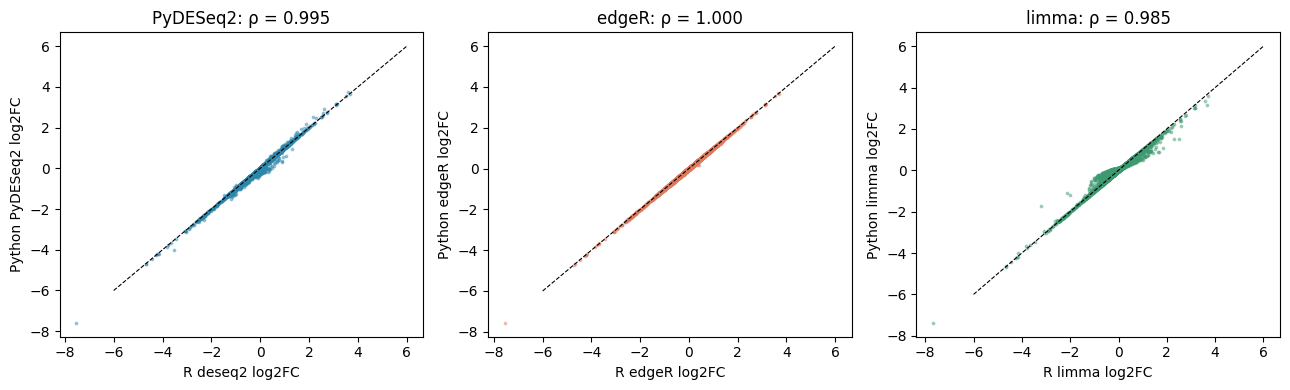

,Python tool,R tool,Python DE,R DE,Shared,Jaccard,Spearman log2FC
0,PyDESeq2,deseq2,5129,5152,5094,0.982,0.9948
1,edgeR,edgeR,5158,5127,5098,0.983,0.9996
2,limma,limma,5162,5223,5073,0.955,0.9855


In [ ]:
# 7. Check B: do the Python tools reproduce the published R results (Schurch et al. 2016, R 3.2.2)?
def read_r(tool):
    r = pd.read_csv(f"data/{tool}_package_default.txt", sep="\t", comment="#", index_col=0)
    return r[["log2foldchange", "significance"]].rename(columns={"log2foldchange": "log2FC", "significance": "padj"})

JAC_MIN, RHO_MIN = 0.90, 0.95                                    # pass thresholds
pairs = {"PyDESeq2": "deseq2", "edgeR": "edgeR", "limma": "limma"}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (m, rt) in zip(axes, pairs.items()):
    r = read_r(rt); py = full[m]; common = py.index.intersection(r.index)
    if rt in ("edgeR", "limma"):          # these R output files report WT vs Snf2, so flip to Snf2 vs WT
        r["log2FC"] = -r["log2FC"]
    a, b = de_set(py.loc[common]), set(r.loc[common].index[r.loc[common, "padj"] < FDR])
    rho = spearmanr(py.loc[common, "log2FC"], r.loc[common, "log2FC"]).correlation
    jac = len(a & b) / len(a | b)
    rows.append({"Python tool": m, "R tool": rt, "Python DE": len(a), "R DE": len(b), "Shared": len(a & b),
                 "Jaccard": round(jac, 3), "Spearman log2FC": round(rho, 4)})
    checks.append({"check": f"B. {m} vs published R {rt}", "value": f"Jaccard {jac:.3f}, rho {rho:.3f}",
                   "pass": jac >= JAC_MIN and rho >= RHO_MIN})
    ax.scatter(r.loc[common, "log2FC"], py.loc[common, "log2FC"], s=3, alpha=.4, color=COLORS[m])
    ax.plot([-6, 6], [-6, 6], "k--", lw=.8)
    ax.set(xlabel=f"R {rt} log2FC", ylabel=f"Python {m} log2FC", title=f"{m}: ρ = {rho:.3f}")
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_python_vs_R.png", dpi=150); plt.show()
py_vs_r = pd.DataFrame(rows); py_vs_r.to_csv(f"{OUT}/table1_python_vs_R.csv", index=False); py_vs_r

In [ ]:
# 8. Check C: pilot draws, cached in cache/ and reused by the benchmark
def get_draw(n, draw):
    """Run all 4 methods on one random draw, or load it from the cache if it was already run."""
    path = f"{CACHE}/n{n:02d}_draw{draw:02d}.csv.gz"
    if os.path.exists(path):
        long = pd.read_csv(path, index_col=0)
    else:
        wt, mut = draw_samples(n, draw)
        long = pd.concat([fn(counts, wt, mut).assign(method=m) for m, fn in RUNNERS.items()])
        long.to_csv(path, float_format="%.6g")
    return {m: long[long["method"] == m][["log2FC", "padj"]] for m in METHODS}

for n in (3, 12):
    t = time.time(); res = get_draw(n, 0); secs = time.time() - t
    ok = all(r["padj"].between(0, 1).all() and r["padj"].notna().all() and len(r) > 5000 for r in res.values())
    ndeg = ", ".join(f"{m} {len(de_set(r))}" for m, r in res.items())
    checks.append({"check": f"C. pilot draw n={n}", "value": f"{secs:.0f}s; DE genes: {ndeg}", "pass": ok})

In [ ]:
# 9. Validation gate: the benchmark only runs if every check passed
val = pd.DataFrame(checks); val.to_csv(f"{OUT}/table0_validation.csv", index=False)
display(val) if "display" in dir() else print(val.to_string())
assert val["pass"].all(), "A validation check failed: fix it before running the benchmark."
print("All validation checks passed. Safe to run the benchmark.")

                               check                                                                value  pass
0       A. TMM vs conorm (full data)                                               max rel. diff 3.53e-04  True
1       A. TMM vs conorm (pilot n=3)                                               max rel. diff 1.91e-06  True
2       A. TMM vs conorm (pilot n=6)                                               max rel. diff 2.44e-04  True
3      A. TMM vs conorm (pilot n=20)                                               max rel. diff 2.82e-04  True
4  B. PyDESeq2 vs published R deseq2                                             Jaccard 0.982, rho 0.995  True
5      B. edgeR vs published R edgeR                                             Jaccard 0.983, rho 1.000  True
6      B. limma vs published R limma                                             Jaccard 0.955, rho 0.985  True
7                  C. pilot draw n=3     43s; DE genes: PyDESeq2 1380, edgeR 1449, limma 1197, Wilcoxon 

<Figure size 640x480 with 0 Axes>

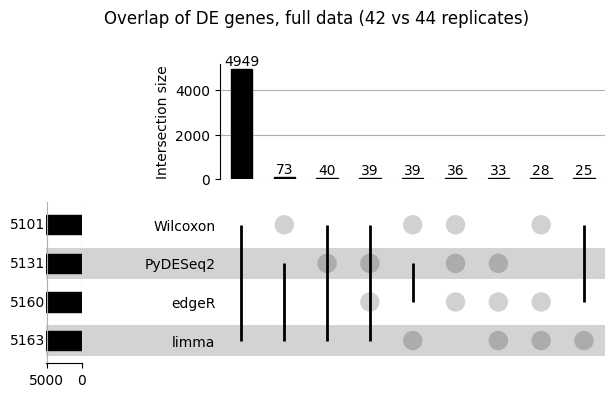

In [ ]:
# 10. Overlap of the full-data reference lists between methods (UpSet plot)
from upsetplot import from_contents, UpSet
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import pandas as pd
import numpy as np

# Construct the contents dataset
contents = {m: de_set(full[m]) for m in METHODS}
plot_data = from_contents(contents)

# Safely cast the MultiIndex back to a clean pandas MultiIndex with standard boolean values.
if isinstance(plot_data.index, pd.MultiIndex):
    clean_tuples = [tuple(bool(x) for x in item) for item in plot_data.index]
    plot_data.index = pd.MultiIndex.from_tuples(clean_tuples, names=METHODS)

# Re-extract the Series data into a clean structure
plot_series = plot_data["id"]

# Clear any existing figure state
plt.clf()

# Generate the UpSet plot using clean boolean index structures
upset = UpSet(plot_series, subset_size="count", show_counts=True,
              sort_by="cardinality", min_subset_size=20,
              facecolor="black", shading_color="lightgray", element_size=40,
              intersection_plot_elements=3, totals_plot_elements=1)

# Target-patch both color and line formatting routines during plot generation
_orig_to_rgba = mcolors.to_rgba
_orig_get_dash_pattern = mlines._get_dash_pattern

def _safe_to_rgba(c, alpha=None):
    try:
        if isinstance(c, float) and np.isnan(c):
            return (0.0, 0.0, 0.0, 0.0)
        if isinstance(c, str) and c.lower() == "nan":
            return (0.0, 0.0, 0.0, 0.0)
    except Exception:
        pass
    return _orig_to_rgba(c, alpha)

def _safe_get_dash_pattern(style):
    if isinstance(style, pd.Series):
        style = style.fillna("solid").tolist()
    if isinstance(style, float) and np.isnan(style):
        return (0, None)
    try:
        return _orig_get_dash_pattern(style)
    except Exception:
        return (0, None)

# Safely handle sequence coordinate inputs directly inside Matplotlib text conversions
import matplotlib.text as mtext
_orig_convert_xunits = mtext.Text.convert_xunits
_orig_convert_yunits = mtext.Text.convert_yunits

def _safe_convert_xunits(self, x):
    res = _orig_convert_xunits(self, x)
    if isinstance(res, (list, tuple, np.ndarray)):
        try:
            return float(np.asarray(res).flat[0])
        except Exception:
            return 0.0
    return res

def _safe_convert_yunits(self, y):
    res = _orig_convert_yunits(self, y)
    if isinstance(res, (list, tuple, np.ndarray)):
        try:
            return float(np.asarray(res).flat[0])
        except Exception:
            return 0.0
    return res

try:
    # Keep patches active for the entire plot-generation, saving, and rendering process
    mcolors.to_rgba = _safe_to_rgba
    mlines._get_dash_pattern = _safe_get_dash_pattern
    mtext.Text.convert_xunits = _safe_convert_xunits
    mtext.Text.convert_yunits = _safe_convert_yunits

    upset.plot()
    plt.suptitle("Overlap of DE genes, full data (42 vs 44 replicates)", y=1.02)
    plt.savefig(f"{OUT}/fig2_upset_full.png", dpi=150, bbox_inches="tight")
    plt.show()
finally:
    # Always cleanly restore the default functions
    mcolors.to_rgba = _orig_to_rgba
    mlines._get_dash_pattern = _orig_get_dash_pattern
    mtext.Text.convert_xunits = _orig_convert_xunits
    mtext.Text.convert_yunits = _orig_convert_yunits

## Step 2: Subsampling benchmark
For each sample size *n*, pick *n* random WT and *n* random Snf2 replicates, run all four methods, and compare the DE
genes found with (a) that method's own full-data **reference** list and (b) the **consensus reference**.

* Raw results of every draw are cached in `cache/` (one file per draw). Re-running loads them instead of recomputing.
* Metrics are saved to `results/subsample_metrics.csv` after every draw, so an interrupted session resumes where it stopped.
* **Metrics:** *recall* = share of the reference list recovered. *Disagreement* = share of a method's calls that are
  NOT in the consensus reference (disagreement with the reference, not a proven biological error).

In [ ]:
# 11. Run the benchmark (the long step; cached draws are skipped)
RUN_FILE = f"{OUT}/subsample_metrics.csv"
done = pd.read_csv(RUN_FILE) if os.path.exists(RUN_FILE) else pd.DataFrame()
big = {m: set(full[m].index[full[m]["log2FC"].abs() > 2]) for m in METHODS}   # strong-effect reference genes
t0 = time.time()
for n in SAMPLE_SIZES:
    for draw in range(N_DRAWS):
        if len(done) and ((done["n"] == n) & (done["draw"] == draw)).any():
            continue                                          # metrics already saved in an earlier session
        res = get_draw(n, draw)
        rows, calls = [], {m: de_set(res[m]) for m in METHODS}
        for m in METHODS:
            ref, found = de_set(full[m]), calls[m]
            rows.append({"n": n, "draw": draw, "method": m, "n_DE": len(found),
                         "recall_own": len(found & ref) / len(ref),
                         "recall_consensus": len(found & consensus) / len(consensus),
                         "disagree_consensus": (len(found - consensus) / len(found)) if found else 0.0,
                         "recall_bigFC": len(found & big[m] & ref) / max(len(big[m] & ref), 1),
                         "recall_smallFC": len((found & ref) - big[m]) / max(len(ref - big[m]), 1)})
        for i, a in enumerate(METHODS):                       # pairwise agreement between methods
            for b in METHODS[i + 1:]:
                u = calls[a] | calls[b]
                rows.append({"n": n, "draw": draw, "method": f"{a}|{b}", "jaccard": len(calls[a] & calls[b]) / len(u) if u else np.nan})
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True); done.to_csv(RUN_FILE, index=False)
        print(f"n={n:2d} draw={draw + 1}/{N_DRAWS}  elapsed {(time.time() - t0) / 60:.1f} min")
runs = done[done["n"].isin(SAMPLE_SIZES) & (done["draw"] < N_DRAWS)]
print("Finished:", runs["draw"].nunique(), "draws per n")

n= 3 draw=1/5  elapsed 0.0 min
n= 3 draw=2/5  elapsed 0.8 min
n= 3 draw=3/5  elapsed 1.6 min
n= 3 draw=4/5  elapsed 2.4 min
n= 3 draw=5/5  elapsed 3.1 min
n= 4 draw=1/5  elapsed 3.9 min
n= 4 draw=2/5  elapsed 4.7 min
n= 4 draw=3/5  elapsed 5.5 min
n= 4 draw=4/5  elapsed 6.3 min
n= 4 draw=5/5  elapsed 7.0 min
n= 6 draw=1/5  elapsed 7.8 min
n= 6 draw=2/5  elapsed 8.6 min
n= 6 draw=3/5  elapsed 9.4 min
n= 6 draw=4/5  elapsed 10.2 min
n= 6 draw=5/5  elapsed 10.9 min
n= 8 draw=1/5  elapsed 11.7 min
n= 8 draw=2/5  elapsed 12.5 min
n= 8 draw=3/5  elapsed 13.3 min
n= 8 draw=4/5  elapsed 14.1 min
n= 8 draw=5/5  elapsed 14.9 min
n=12 draw=1/5  elapsed 14.9 min
n=12 draw=2/5  elapsed 15.7 min
n=12 draw=3/5  elapsed 16.5 min
n=12 draw=4/5  elapsed 17.3 min
n=12 draw=5/5  elapsed 18.1 min
n=20 draw=1/5  elapsed 19.0 min
n=20 draw=2/5  elapsed 19.9 min
n=20 draw=3/5  elapsed 20.7 min
n=20 draw=4/5  elapsed 21.6 min
n=20 draw=5/5  elapsed 22.4 min
Finished: 5 draws per n


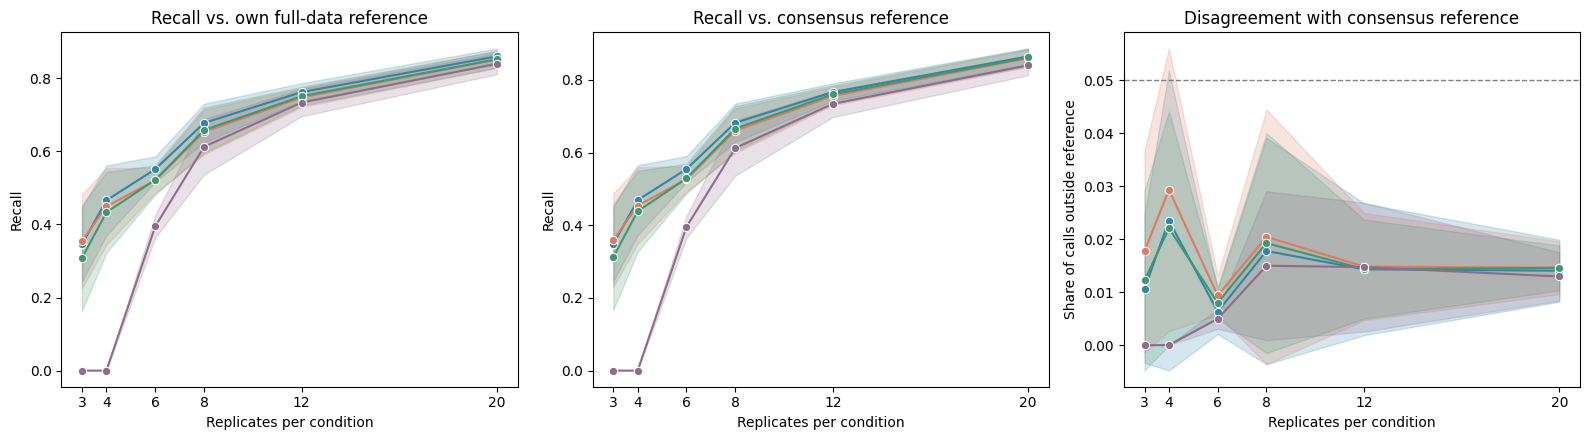

In [ ]:
# 12. Figure: recall and disagreement vs. number of replicates
per = runs[runs["method"].isin(METHODS)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, col, title in zip(axes, ["recall_own", "recall_consensus", "disagree_consensus"],
                          ["Recall vs. own full-data reference", "Recall vs. consensus reference", "Disagreement with consensus reference"]):
    sns.lineplot(data=per, x="n", y=col, hue="method", palette=COLORS, marker="o", errorbar="sd", ax=ax)
    ax.set(title=title, xlabel="Replicates per condition", ylabel="Recall" if col.startswith("recall") else "Share of calls outside reference")
    ax.set_xticks(SAMPLE_SIZES)
axes[2].axhline(FDR, ls="--", color="grey", lw=1)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_recall_vs_n.png", dpi=150); plt.show()

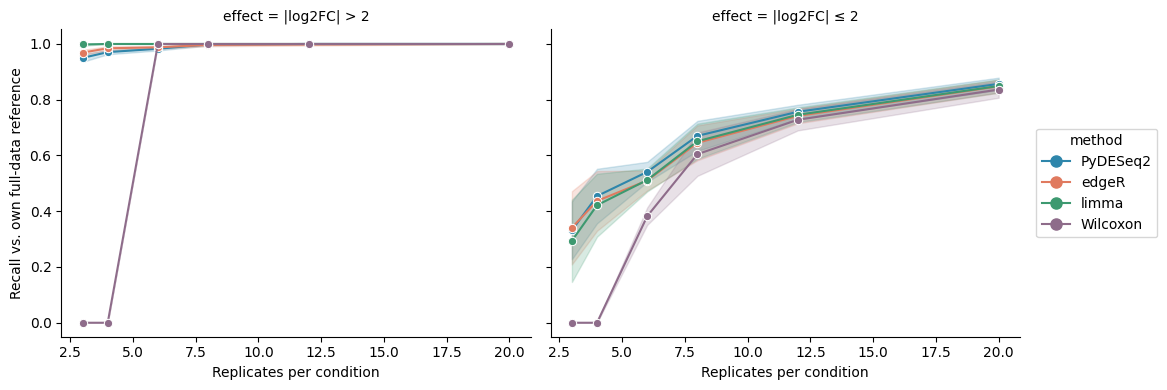

In [ ]:
# 13. Figure: strong vs. weak effects (|log2FC| > 2 vs. smaller)
long = per.melt(id_vars=["n", "method"], value_vars=["recall_bigFC", "recall_smallFC"], var_name="effect", value_name="recall")
long["effect"] = long["effect"].map({"recall_bigFC": "|log2FC| > 2", "recall_smallFC": "|log2FC| ≤ 2"})

# Disable seaborn's auto-legend to bypass the unpacking error in newer Matplotlib versions
g = sns.relplot(data=long, x="n", y="recall", hue="method", col="effect", kind="line", marker="o", palette=COLORS,
                errorbar="sd", height=4, aspect=1.3, legend=False)

g.set_axis_labels("Replicates per condition", "Recall vs. own full-data reference")

# Manually add the legend to prevent the compatibility crash
legend_handles = [plt.Line2D([0], [0], marker='o', color=color, label=method, markersize=8) for method, color in COLORS.items()]
g.axes.flat[-1].legend(handles=legend_handles, title="method", loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.savefig(f"{OUT}/fig4_recall_by_effect_size.png", dpi=150, bbox_inches="tight")
plt.show()

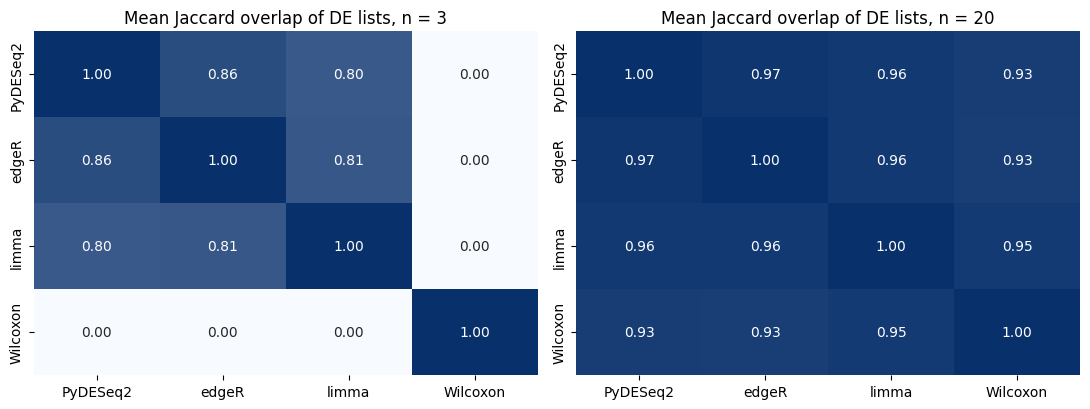

In [ ]:
# 14. Figure: how much do the methods agree with each other?
pw = runs[runs["method"].str.contains("|", regex=False)].copy()
pw[["A", "B"]] = pw["method"].str.split("|", expand=True)

import matplotlib as mpl
import matplotlib.colors as mcolors

# Create a clean, custom colormap manually to bypass the corrupted colormap registry entirely
custom_blues = mcolors.LinearSegmentedColormap.from_list("custom_blues", ["#f7fbff", "#08306b"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, n in zip(axes, [min(SAMPLE_SIZES), max(SAMPLE_SIZES)]):
    mat = pd.DataFrame(1.0, index=METHODS, columns=METHODS)
    for _, r in pw[pw["n"] == n].groupby(["A", "B"])["jaccard"].mean().reset_index().iterrows():
        mat.loc[r.A, r.B] = mat.loc[r.B, r.A] = r.jaccard
    sns.heatmap(mat, annot=True, fmt=".2f", vmin=0, vmax=1, cmap=custom_blues, ax=ax, cbar=False)
    ax.set_title(f"Mean Jaccard overlap of DE lists, n = {n}")
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_agreement_heatmaps.png", dpi=150); plt.show()

In [ ]:
# 15. Summary tables: mean recall per method and n, and minimum n to reach 50% / 80% recall
summary = per.groupby(["method", "n"])[["n_DE", "recall_own", "recall_consensus", "disagree_consensus"]].mean().round(3)
summary.to_csv(f"{OUT}/table2_summary_by_n.csv"); display(summary) if "display" in dir() else print(summary)

def min_n(df, target):
    ok = df[df["recall_own"] >= target]
    return int(ok["n"].min()) if len(ok) else f">{max(SAMPLE_SIZES)}"
mean_rec = per.groupby(["method", "n"])["recall_own"].mean().reset_index()
rec = pd.DataFrame({"Min replicates for 50% recall": {m: min_n(mean_rec[mean_rec.method == m], .5) for m in METHODS},
                    "Min replicates for 80% recall": {m: min_n(mean_rec[mean_rec.method == m], .8) for m in METHODS}})
rec.to_csv(f"{OUT}/table3_min_replicates.csv"); print(rec)

               n_DE  recall_own  recall_consensus  disagree_consensus
method   n                                                           
PyDESeq2 3   1797.2       0.346             0.348               0.011
         4   2452.2       0.466             0.469               0.024
         6   2842.0       0.551             0.555               0.006
         8   3538.4       0.678             0.682               0.018
         12  3960.6       0.762             0.766               0.014
         20  4462.8       0.860             0.864               0.014
Wilcoxon 3      0.0       0.000             0.000               0.000
         4      0.0       0.000             0.000               0.000
         6   2023.0       0.395             0.395               0.005
         8   3169.8       0.613             0.613               0.015
         12  3795.6       0.734             0.734               0.015
         20  4334.8       0.840             0.840               0.013
edgeR    3   1870.2 

In [ ]:
# 16. Zip everything for download (Files panel on the left -> results.zip -> Download)
import shutil
shutil.make_archive("results", "zip", OUT)
print("Saved results.zip")

Saved results.zip
